# CLUMPY Commands for Extragalactic Sources

For **extragalactic halos**, the CLUMPY tutorial recommends using the `-h` option.

## 1. Configure the halo parameters

To generate a **2D skymap** of your source, you first need to create or edit a parameter file containing the properties of your halo:

* **Name** and **type** of the object (e.g. `dSph` for a dwarf spheroidal galaxy).
* **Equatorial coordinates** of the source.
* **Distance** to the source.
* **Scale radius** $r_s$
* **Density** $\rho(r_s)$ at the scale radius $r_s$.
* **Outer halo radius**.
* Optional **triaxiality** parameters.
* Halo profile parameters ($\alpha$, $\beta$, $\gamma$) defining the **Zhao profile**.

### Zhao density profile

$$
\rho(r)=\frac{\rho_s}{\left(\frac{r}{r_0}\right)^\gamma
\left[1+\left(\frac{r}{r_s}\right)^\alpha\right]^{(\beta-\gamma)/\alpha}}
$$

where:

* $r_s$ is the scale radius,
* $\rho_0$ is the characteristic density,
* $\alpha$, $\beta$, and $\gamma$ determine the inner slope, outer slope, and transition of the profile.

## 2. Configure the CLUMPY parameters

The second required file is `clumpy_params_h3.txt`, which specifies:

* Whether to include **dark matter clumps** (required to produce 2D ($dJ/d\Omega$) skymaps).
* The dark matter scenario:

  * **Annihilation**
  * **Decay**.
* The desired **field of view (FoV)**.
* The **HEALPix** map resolution.

## 3. Generate the skymap

Once the parameter files are ready, generate the 2D skymap with:

```bash
clumpy -i -h3 clumpy_h3_parameter.txt
```

A default parameter file can also be generated automatically (this is recommended as a starting point). You can then modify it according to your needs:

```bash
clumpy -i -h3D
```

## Additional information

This page provides a brief overview of the main options required to start working with **CLUMPY** for extragalactic sources. For a complete description of all parameters and available options, refer to the official documentation:

[CLUMPY documentation (v3.1.1)](https://clumpy.gitlab.io/CLUMPY/v3.1.1/?utm_source=chatgpt.com)


## Code to read the output of CLUMPY using (Based on clumpy tutorials)

In [10]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import numpy as np 

import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord

import healpy as hp

from gammapy.maps import (
    Map,
    WcsGeom,
)
from gammapy.modeling.models import (
    TemplateSpatialModel
)

## For J-factor map

In [ ]:
filename = "name of the output"

target_position = SkyCoord.from_name("Target")

col=1
ext=1

data = hp.read_map(filename, partial=True, hdu=ext, field=col-1)
data[data < 1] = 1e-40

hdulist = fits.open(filename)
dtheta = hdulist[ext].header['SIZE_Y']
print(dtheta)
dtheta_orth = hdulist[ext].header['SIZE_X']
title = hdulist[ext].header['TTYPE'+str(col+1)]
units = hdulist[ext].header['TUNIT'+str(col+1)]
hdulist.close()

map_jfact = hp.cartview(data, 
            lonra=[-dtheta_orth/2,dtheta_orth/2], latra=[-dtheta/2,dtheta/2], 
            norm='log', 
            max=data.max(), title=title, unit=units, return_projected_map=True)
plt.show()

### Convertion into WCS map

In [ ]:
skydir = SkyCoord(target_position.ra, target_position.dec, unit="deg", frame="icrs")

DM_map_jfact = Map.create(
    binsz=0.0025,
    width=(2, 2), skydir=skydir, 
    frame="icrs", proj="CAR",
    unit = "GeV2 cm-5"
)
print(DM_map_jfact.geom)

DM_map_jfact.data = map_jfact 
DM_map_jfact.plot(add_cbar=True, norm=LogNorm())
plt.show()

geom = WcsGeom.create(
    skydir=skydir,
    binsz=0.02,
    width=(3, 3),
    frame="icrs",
)

### Creation of the spatial template model 

In [ ]:
spatial_model = TemplateSpatialModel(DM_map_jfact, geom,normalize = True)
spatial_model.plot(add_cbar=True, norm=LogNorm())

### Computation of the total J-factor (possibility to integrate to a certain angle)

In [ ]:
nside = hp.get_nside(data)

pix_area_sr = hp.nside2pixarea(nside, degrees=False)

mask_valid = np.isfinite(data) & (data > 1e-40)

J_total = np.sum(data[mask_valid]) * u.Unit("GeV2 cm-5")

print(f"Nside                 = {nside}")
print(f"Area of a pixel       = {pix_area_sr:.3e} sr")
print(f"J total               = {J_total:.4e}")
print(f"log10(J total)        = {np.log10(J_total.value):.4f}")

## For D-Factor map


2.0


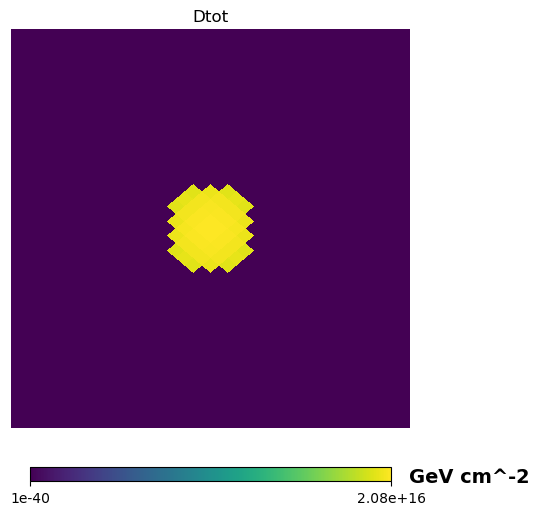

WcsGeom

	axes       : ['lon', 'lat']
	shape      : (np.int64(800), np.int64(800))
	ndim       : 2
	frame      : icrs
	projection : CAR
	center     : 168.4 deg, 22.2 deg
	width      : 2.0 deg x 2.0 deg
	wcs ref    : 168.4 deg, 22.2 deg



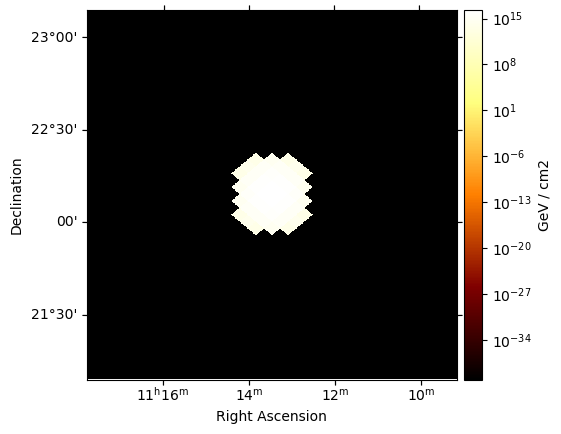

In [ ]:

filename = "name of the output"

target_position = SkyCoord.from_name("Target")

col=1
ext=1

data = hp.read_map(filename, partial=True, hdu=ext, field=col-1)
data[data < 1] = 1e-40

hdulist = fits.open(filename)
dtheta = hdulist[ext].header['SIZE_Y']
print(dtheta)
dtheta_orth = hdulist[ext].header['SIZE_X']
title = hdulist[ext].header['TTYPE'+str(col+1)]
units = hdulist[ext].header['TUNIT'+str(col+1)]
hdulist.close()

map_jfact = hp.cartview(data, 
            lonra=[-dtheta_orth/2,dtheta_orth/2], latra=[-dtheta/2,dtheta/2], 
            norm='log', 
            max=data.max(), title=title, unit=units, return_projected_map=True)
plt.show()

### Convertion into WCS map

WcsGeom

	axes       : ['lon', 'lat']
	shape      : (np.int64(800), np.int64(800))
	ndim       : 2
	frame      : icrs
	projection : CAR
	center     : 168.4 deg, 22.2 deg
	width      : 2.0 deg x 2.0 deg
	wcs ref    : 168.4 deg, 22.2 deg



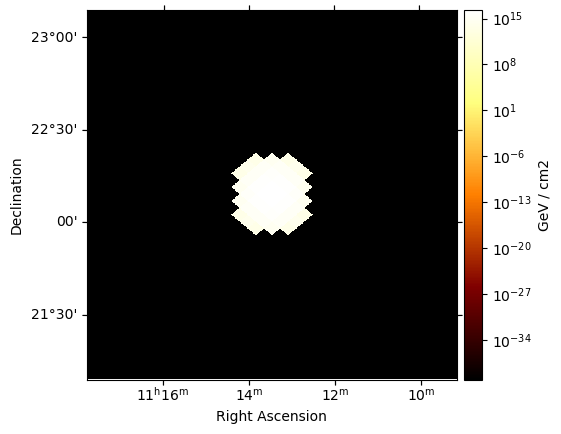

In [8]:
skydir = SkyCoord(target_position.ra, target_position.dec, unit="deg", frame="icrs")

DM_map_jfact = Map.create(
    binsz=0.0025,
    width=(2, 2), skydir=skydir, 
    frame="icrs", proj="CAR",
    unit = "GeV cm-2"
)
print(DM_map_jfact.geom)

DM_map_jfact.data = map_jfact 
DM_map_jfact.plot(add_cbar=True, norm=LogNorm())
plt.show()

geom = WcsGeom.create(
    skydir=skydir,
    binsz=0.02,
    width=(3, 3),
    frame="icrs",
)

### Creation of the template spatial model

The filename is not defined. Therefore, the model will not be serialised correctly. To set the filename, the "template_model.filename" attribute can be used.


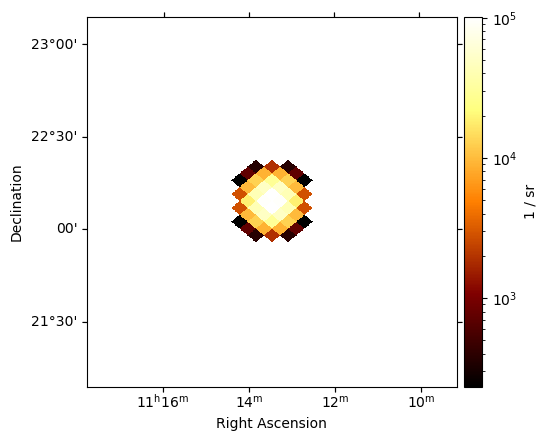

In [9]:
spatial_model = TemplateSpatialModel(DM_map_jfact, geom,normalize = True)
spatial_model.plot(add_cbar=True, norm=LogNorm())

### Computation of the total D-factor (possibility to integrate over a certain angle)

In [11]:
nside = hp.get_nside(data)

pix_area_sr = hp.nside2pixarea(nside, degrees=False)

mask_valid = np.isfinite(data) & (data > 1e-40)

J_total = np.sum(data[mask_valid]) * u.Unit("GeV cm-2")

print(f"Nside                 = {nside}")
print(f"Area of a pixel       = {pix_area_sr:.3e} sr")
print(f"J total               = {J_total:.4e}")
print(f"log10(J total)        = {np.log10(J_total.value):.4f}")

Nside                 = 1024
Area of a pixel       = 9.987e-07 sr
J total               = 2.0657e+17 GeV / cm2
log10(J total)        = 17.3151
